# SANOS Intraday Fitting

Fits the SANOS arbitrage-free option surface **continuously throughout a trading day** on the front SPY expiry.

- **Two geometry modes**: `GridGeometry` (fixed NMS grid) and `OpenGeometry` (market-adaptive, built from first-batch strikes)
- **Independent fits**: calls and puts fitted separately — no put-call parity stitching
- **Evaluation**: SANOS-fitted prices vs actual trades — normalized price error + IV error


In [1]:
import bisect
import importlib as imp
import os
import sys
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

project_root = "/Users/elie/Documents/GitHub/quant_data/"
if project_root not in sys.path:
    sys.path.insert(0, project_root)

sanos_dir = os.path.join(project_root, "personal", "Kalman_filter_spline", "SANOS")
if sanos_dir not in sys.path:
    sys.path.insert(0, sanos_dir)

os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"
os.environ["QUANTDATA_TRAINING_DATA"] = "!/quantdata/training"
os.environ["QUANTDATA_PROCESSING_DATA"] = "!/quantdata/processing"
os.environ["QUANTDATA_CACHE_MODE"] = "on"
os.environ["QUANTDATA_TEST_MODE"] = "0"

import quantdata as _qd

imp.reload(_qd)
import sanos_option

from quantdata.biz_calendar import DAYS_PER_YEAR, NMS
from quantdata.massive.client import MassiveClient
from quantdata.sanos.fitter import Fitter
from quantdata.sanos.grid import GridGeometry, GridSanos
from quantdata.sanos.open import OpenGeometryGenerator, OpenSanos
from quantdata.utils.backbone import BackboneNumpy

imp.reload(sanos_option)

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


<module 'sanos_option' from '/Users/elie/Documents/GitHub/quant_data/personal/Kalman_filter_spline/SANOS/sanos_option.py'>

## Parameters

In [8]:
TICKER = "SPY"
TRADE_DATE = date(2024, 1, 3)
BATCH_FREQ = "1m"  # 'tick' | '1s' | '1m' | '5m'
N_VIZ = 4  # timestamps to visualize in the smile cell

# GridGeometry parameters
NMS_RANGE = 3.5  # symmetric NMS range
NUM_NMS = 13  # number of inner model strikes
LOWER_SCALE = 0.1  # lower boundary = LOWER_SCALE * lowest_inner_strike
UPPER_SCALE = 2.0  # upper boundary = UPPER_SCALE * highest_inner_strike

# Three DLV bound configurations for tight/current/loose comparison
DLV_CONFIGS = {
    "tight": dict(dlv_min=0.10, dlv_max=2.0),
    "current": dict(dlv_min=0.01, dlv_max=5.0),
    "loose": dict(dlv_min=0.0001, dlv_max=500.0),
}
CFG_COLORS = {"tight": "darkorange", "current": "steelblue", "loose": "seagreen"}

## Data loading

Reuses `build_option_observations` from `sanos_option.py`: fetches quotes + trades, estimates intraday forward via 2x2 put-call parity, tags each row with `T`, `forward`, `discount_factor`, `log_moneyness`.

In [9]:
df_tickers = pl.read_csv(os.path.join(project_root, "personal", "spy_options_tickers.csv"))
client = MassiveClient()
df_spy = client.fetch_trades(TICKER, TRADE_DATE)

df_quotes, df_trades = sanos_option.build_option_observations(
    df_tickers=df_tickers,
    trade_date=TRADE_DATE,
    df_spy=df_spy,
    min_trades=100,
    simple=False,
)
print(f"Quotes: {df_quotes.shape[0]:,} rows | Trades: {df_trades.shape[0]:,} rows")
print(f"Unique strikes: {df_quotes['strike'].n_unique()}")
df_quotes.head(3)

Skipping O:SPY240105C00481000: 46 bad quotes
Skipping O:SPY240105C00482000: 64 bad quotes
Skipping O:SPY240105C00483000: 842 bad quotes
Skipping O:SPY240105C00484000: 2129 bad quotes
Skipping O:SPY240105C00485000: 3888 bad quotes
Skipping O:SPY240105P00462500: 17 bad quotes
Expiry 2024-01-05: forward from 13 overlapping strike(s)
Quotes: 2,115,510 rows | Trades: 74,099 rows
Unique strikes: 25


ts_ns,strike,is_call,log_moneyness,T,observed_price,bid_price,ask_price,forward,discount_factor
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.100339,0.09,0.11,470.43,1.0
2024-01-03 09:30:00.008294144 EST,471.0,false,0.001211,0.006217,2.19,2.17,2.21,470.43,1.0
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.105,0.08,0.13,470.43,1.0


## Front expiry — filter, normalize, split calls/puts

In [10]:
# Identify front expiry: smallest T bucket at 0.01-yr resolution (~2.5 trading days)
# T_bucket_expr = (pl.col("T") * 100).round(0) / 100

# expiry_stats = (
#     df_quotes.with_columns(T_bucket_expr.alias("T_r"))
#     .group_by("T_r")
#     .agg([pl.col("T").median().alias("T_med"), pl.len().alias("n")])
#     .sort("T_r")
# )
# print("Expiry buckets found:")
# print(expiry_stats)

# front_T_r = float(expiry_stats.head(1)["T_r"][0])
# df_q_front = df_quotes.filter(T_bucket_expr == front_T_r)
# df_t_front = df_trades.filter(T_bucket_expr == front_T_r)


# Single expiry — no bucketing needed, take all quotes/trades
df_q_front = df_quotes
df_t_front = df_trades
tte_y_max = df_quotes["T"].max()


tte_y_max = float(df_q_front["T"].max())  # TTE at market open (geometry needs to cover this)
tte_y_med = float(df_q_front["T"].median())  # representative TTE
tte_geom = tte_y_max * 1.1  # geometry expiry: 10% buffer above max observed TTE

print(
    f"\nFront expiry: TTE max={tte_y_max:.5f} yr ({tte_y_max * 252:.2f} td), "
    f"median={tte_y_med:.5f} yr"
)
print(f"Geometry expiry (with 10% buffer): {tte_geom:.5f} yr")
print(f"Front quotes: {df_q_front.shape[0]:,}  |  Front trades: {df_t_front.shape[0]:,}")

# Add normalized price columns
df_q_front = df_q_front.with_columns(
    [
        pl.col("log_moneyness").exp().alias("pure_strike"),
        (pl.col("forward") * pl.col("discount_factor")).alias("scale"),
    ]
).with_columns(
    [
        (pl.col("bid_price") / pl.col("scale")).alias("bid_norm"),
        (pl.col("ask_price") / pl.col("scale")).alias("ask_norm"),
        ((pl.col("bid_price") + pl.col("ask_price")) / 2.0 / pl.col("scale")).alias("mid_norm"),
    ]
)

# Split calls and puts
df_calls = df_q_front.filter(pl.col("is_call")).sort("ts_ns")
df_puts = df_q_front.filter(~pl.col("is_call")).sort("ts_ns")
df_trades_calls = df_t_front.filter(pl.col("is_call")).sort("ts_ns")
df_trades_puts = df_t_front.filter(~pl.col("is_call")).sort("ts_ns")

print(f"\nCalls: {df_calls['strike'].n_unique()} strikes, {df_calls.shape[0]:,} rows")
print(f"Puts:  {df_puts['strike'].n_unique()} strikes, {df_puts.shape[0]:,} rows")
print(f"Call trades: {df_trades_calls.shape[0]:,}  |  Put trades: {df_trades_puts.shape[0]:,}")


Front expiry: TTE max=0.00622 yr (1.57 td), median=0.00582 yr
Geometry expiry (with 10% buffer): 0.00684 yr
Front quotes: 2,115,510  |  Front trades: 74,099

Calls: 17 strikes, 956,399 rows
Puts:  21 strikes, 1,159,111 rows
Call trades: 35,069  |  Put trades: 39,030


## Batch snapshots

Group quotes into time windows. For each window x strike, keep the **last** quote (most recent before batch end).

In [11]:
def make_batch_snapshots(df, batch_freq):
    if batch_freq == "tick":
        df = df.with_columns(pl.col("ts_ns").alias("batch_ts"))
    elif batch_freq == "1s":
        df = df.with_columns(pl.col("ts_ns").dt.truncate("1s").alias("batch_ts"))
    elif batch_freq == "1m":
        df = df.with_columns(pl.col("ts_ns").dt.truncate("1m").alias("batch_ts"))
    elif batch_freq == "5m":
        df = df.with_columns(pl.col("ts_ns").dt.truncate("5m").alias("batch_ts"))
    else:
        raise ValueError(f"Unknown BATCH_FREQ: {batch_freq!r}")

    return (
        df.sort("ts_ns")
        .group_by(["batch_ts", "strike"])
        .agg(
            [
                pl.col("pure_strike").last(),
                pl.col("bid_norm").last(),
                pl.col("ask_norm").last(),
                pl.col("mid_norm").last(),
                pl.col("T").last(),
            ]
        )
        .sort(["batch_ts", "strike"])
    )


snaps_calls = make_batch_snapshots(df_calls, BATCH_FREQ)
snaps_puts = make_batch_snapshots(df_puts, BATCH_FREQ)

batch_ts_c = set(snaps_calls["batch_ts"].unique().to_list())
batch_ts_p = set(snaps_puts["batch_ts"].unique().to_list())
batch_ts_list = sorted(batch_ts_c & batch_ts_p)

print(f"BATCH_FREQ = {BATCH_FREQ!r}")
print(f"Batches with both calls+puts present: {len(batch_ts_list)}")
print(f"Calls-only batches: {len(batch_ts_c - batch_ts_p)}")
print(f"Puts-only batches:  {len(batch_ts_p - batch_ts_c)}")

BATCH_FREQ = '1m'
Batches with both calls+puts present: 405
Calls-only batches: 0
Puts-only batches:  0


## Build SANOS geometries

### GridGeometry (T=1)
Fixed NMS strike grid, manually constructed for a single expiry.
Shared across all batches — strikes are forward-normalized (pure strikes, not dollar strikes).

### OpenGeometry (T=1)
Market-adaptive: strike grid built backwards from the initial batch's quoted strikes.
Created once from the first batch; rebuilding per-batch is possible but slow.

In [12]:
# ── GridGeometry (T=1, manually constructed) ──────────────────────────────────
nms_vals = np.linspace(-NMS_RANGE, NMS_RANGE, NUM_NMS)  # e.g. 13 NMS values
t_vals = np.array([0.0, tte_geom])

# Inner strikes at each expiry: shape (2, NUM_NMS)
inner_strikes = NMS.from_nms(nms_vals[None, :], t=t_vals[:, None])

lower = (LOWER_SCALE * inner_strikes[:, 0]).reshape(-1, 1)  # shape (2,1)
upper = (UPPER_SCALE * inner_strikes[:, -1]).reshape(-1, 1)  # shape (2,1)
xstrikes = np.concatenate([lower, inner_strikes, upper], axis=1)  # (2, NUM_NMS+2)

assert np.all(np.diff(xstrikes[:, 0]) <= 0), "Lower boundary must be non-increasing in time"
assert np.all(np.diff(xstrikes[:, -1]) >= 0), "Upper boundary must be non-decreasing in time"
assert np.all(xstrikes[:, 1] < 1.0), "Second column must be < 1 (below ATM)"
assert np.all(xstrikes[:, -2] > 1.0), "Second-to-last column must be > 1 (above ATM)"

grid_geom = GridGeometry(
    xexpiries=t_vals,
    xstrikes=xstrikes,
    dlv_min=0.01,
    dlv_max=5.0,
    vol_interp="lin_var",
)
print(f"GridGeometry: T={grid_geom.T}, N={grid_geom.N}  (shape {grid_geom.xstrikes.shape})")
print(f"  Inner strikes at tte_geom: {np.round(grid_geom.xstrikes[1, 1:-1], 4)}")

grid_fitter_c = Fitter(geometry=grid_geom, max_error=None, no_warnings=True)
grid_fitter_p = Fitter(geometry=grid_geom, max_error=None, no_warnings=True)
grid_sanos_c = GridSanos(geometry=grid_geom, bb=BackboneNumpy())
grid_sanos_p = GridSanos(geometry=grid_geom, bb=BackboneNumpy())

# ── OpenGeometry (T=1, market-adaptive) ───────────────────────────────────────
first_ts = batch_ts_list[0]
init_c = snaps_calls.filter(pl.col("batch_ts") == first_ts).sort("pure_strike")
init_p = snaps_puts.filter(pl.col("batch_ts") == first_ts).sort("pure_strike")

open_gen = OpenGeometryGenerator(
    dlv_min=0.01,
    dlv_max=5.0,
    vol_interp="lin_var",
    lower_scale=LOWER_SCALE,
    upper_scale=UPPER_SCALE,
    min_dx=1e-4,
)

# Extend the initial strike range to cover the full dense pricing grid so that
# strikes in pk_dense (log_k in [-0.22, 0.12]) fall inside the model interior,
# not at or below next_mstrk[1], which would trigger UserWarnings.
_pk_min = np.exp(-0.25)  # slightly below the log_k_dense lower bound of -0.22
_pk_max = np.exp(+0.15)  # slightly above the log_k_dense upper bound of +0.12


def _extend_strikes(arr: np.ndarray, lo: float, hi: float) -> np.ndarray:
    arr = np.asarray(arr, dtype=np.float64)
    if arr[0] > lo:
        arr = np.concatenate([[lo], arr])
    if arr[-1] < hi:
        arr = np.concatenate([arr, [hi]])
    return arr


init_pk_c = _extend_strikes(init_c["pure_strike"].to_numpy(), _pk_min, _pk_max)
init_pk_p = _extend_strikes(init_p["pure_strike"].to_numpy(), _pk_min, _pk_max)

open_geom_c = open_gen.create_arb_free_geometry(
    expiries=np.array([tte_geom]),
    pure_strikes=[init_pk_c],
)
open_geom_p = open_gen.create_arb_free_geometry(
    expiries=np.array([tte_geom]),
    pure_strikes=[init_pk_p],
)
print(
    f"OpenGeometry calls: T={open_geom_c.T}, model strikes={[len(s) for s in open_geom_c.strikes]}"
)
print(
    f"OpenGeometry puts:  T={open_geom_p.T}, model strikes={[len(s) for s in open_geom_p.strikes]}"
)

open_fitter_c = Fitter(geometry=open_geom_c, max_error=None, no_warnings=True)
open_fitter_p = Fitter(geometry=open_geom_p, max_error=None, no_warnings=True)
open_sanos_c = OpenSanos(geometry=open_geom_c, no_warnings=True)
open_sanos_p = OpenSanos(geometry=open_geom_p, no_warnings=True)

# ── Three DLV bound configs (open geometry, market-adaptive strikes) ──────────
dlv_geoms = {}
dlv_fitters = {}
dlv_sanos = {}

print("Building DLV-config geometries:")
for cfg_name, cfg_params in DLV_CONFIGS.items():
    gen = OpenGeometryGenerator(
        vol_interp="lin_var",
        lower_scale=LOWER_SCALE,
        upper_scale=UPPER_SCALE,
        min_dx=1e-4,
        **cfg_params,
    )
    geom_c = gen.create_arb_free_geometry(
        expiries=np.array([tte_geom]),
        pure_strikes=[init_pk_c],
    )
    geom_p = gen.create_arb_free_geometry(
        expiries=np.array([tte_geom]),
        pure_strikes=[init_pk_p],
    )
    dlv_geoms[cfg_name] = {"c": geom_c, "p": geom_p}
    dlv_fitters[cfg_name] = {
        "c": Fitter(geometry=geom_c, max_error=None, no_warnings=True),
        "p": Fitter(geometry=geom_p, max_error=None, no_warnings=True),
    }
    dlv_sanos[cfg_name] = {
        "c": OpenSanos(geometry=geom_c, no_warnings=True),
        "p": OpenSanos(geometry=geom_p, no_warnings=True),
    }
    print(
        f"  {cfg_name:8s}: dlv_min={cfg_params['dlv_min']:.3f}  dlv_max={cfg_params['dlv_max']:.1f}  "
        f"inner_strikes calls={len(init_pk_c)}  puts={len(init_pk_p)}"
    )


print(f"DLV configs ready: {list(DLV_CONFIGS.keys())}")

GridGeometry: T=1, N=13  (shape (2, 15))
  Inner strikes at tte_geom: [0.9719 0.9765 0.9811 0.9858 0.9905 0.9953 1.     1.0048 1.0096 1.0144
 1.0192 1.0241 1.029 ]
OpenGeometry calls: T=1, model strikes=[19]
OpenGeometry puts:  T=1, model strikes=[23]
Building DLV-config geometries:
  tight   : dlv_min=0.100  dlv_max=2.0  inner_strikes calls=19  puts=23
  current : dlv_min=0.010  dlv_max=5.0  inner_strikes calls=19  puts=23
  loose   : dlv_min=0.000  dlv_max=500.0  inner_strikes calls=19  puts=23
DLV configs ready: ['tight', 'current', 'loose']


## Intraday fitting loop

For each batch: 4 LP/QP solves (Grid calls, Grid puts, Open calls, Open puts).

Forward vol (`fwd_vols`) is estimated per batch from the nearest-ATM mid price via a scalar BS inversion. `Fitter` internally converts put prices to call space before solving.

In [13]:
try:
    from tqdm.auto import tqdm
except ImportError:

    def tqdm(x, **kw):
        return x


def compute_atm_iv(pure_strikes, mid_norms, tte, is_call=True):
    """Estimate ATM IV from nearest-ATM quote using scalar BS inversion."""
    log_k = np.log(np.asarray(pure_strikes, dtype=float))
    idx = int(np.argmin(np.abs(log_k)))
    fn = sanos_option._iv_from_norm_call if is_call else sanos_option._iv_from_norm_put
    iv = fn(float(mid_norms[idx]), float(log_k[idx]), float(tte))
    return float(iv) if np.isfinite(iv) and iv > 0 else 0.20


results = []
n_failed = {
    "grid_c": 0,
    "grid_p": 0,
    "open_c": 0,
    "open_p": 0,
    **{f"dlv_{cfg}_{side}": 0 for cfg in DLV_CONFIGS for side in ["c", "p"]},
}

for batch_ts in tqdm(batch_ts_list, desc="Fitting batches"):
    snap_c = snaps_calls.filter(pl.col("batch_ts") == batch_ts).sort("pure_strike")
    snap_p = snaps_puts.filter(pl.col("batch_ts") == batch_ts).sort("pure_strike")
    if snap_c.is_empty() or snap_p.is_empty():
        continue

    pk_c = snap_c["pure_strike"].to_numpy().astype(np.float64)
    bid_c = snap_c["bid_norm"].to_numpy().astype(np.float64)
    ask_c = snap_c["ask_norm"].to_numpy().astype(np.float64)
    tte_c = snap_c["T"].to_numpy().astype(np.float64)
    mid_c = (bid_c + ask_c) / 2

    pk_p = snap_p["pure_strike"].to_numpy().astype(np.float64)
    bid_p = snap_p["bid_norm"].to_numpy().astype(np.float64)
    ask_p = snap_p["ask_norm"].to_numpy().astype(np.float64)
    tte_p = snap_p["T"].to_numpy().astype(np.float64)
    mid_p = (bid_p + ask_p) / 2

    ok_c = (bid_c < ask_c) & (bid_c > 0) & np.isfinite(bid_c) & np.isfinite(ask_c)
    ok_p = (bid_p < ask_p) & (bid_p > 0) & np.isfinite(bid_p) & np.isfinite(ask_p)
    if ok_c.sum() < 3 or ok_p.sum() < 3:
        continue

    tte_c_med = float(np.median(tte_c[ok_c]))
    tte_p_med = float(np.median(tte_p[ok_p]))

    # Forward vols: ATM IV at this snapshot's TTE (scalar sigma, not sigma*sqrt(T))
    fwdvols_c = np.array([compute_atm_iv(pk_c[ok_c], mid_c[ok_c], tte_c_med, is_call=True)])
    fwdvols_p = np.array([compute_atm_iv(pk_p[ok_p], mid_p[ok_p], tte_p_med, is_call=False)])

    row = {
        "ts": batch_ts,
        "atm_iv_c": float(fwdvols_c[0]),
        "atm_iv_p": float(fwdvols_p[0]),
        "n_c": int(ok_c.sum()),
        "n_p": int(ok_p.sum()),
    }

    # Grid + Open geometry fits (existing)
    for gname, fc, fp in [
        ("grid", grid_fitter_c, grid_fitter_p),
        ("open", open_fitter_c, open_fitter_p),
    ]:
        try:
            dlvsqs_c = fc(fwdvols_c, pk_c[ok_c], bid_c[ok_c], ask_c[ok_c], tte_c[ok_c])
            row[f"{gname}_dlvsqs_c"] = dlvsqs_c
            row[f"{gname}_fwdvols_c"] = fwdvols_c.copy()
        except Exception:
            row[f"{gname}_dlvsqs_c"] = None
            n_failed[f"{gname}_c"] += 1

        try:
            dlvsqs_p = fp(
                fwdvols_p,
                pk_p[ok_p],
                bid_p[ok_p],
                ask_p[ok_p],
                tte_p[ok_p],
                opt_is_calls=np.zeros(ok_p.sum(), dtype=bool),
            )
            row[f"{gname}_dlvsqs_p"] = dlvsqs_p
            row[f"{gname}_fwdvols_p"] = fwdvols_p.copy()
        except Exception:
            row[f"{gname}_dlvsqs_p"] = None
            n_failed[f"{gname}_p"] += 1

    # DLV bound config fits (open geometry, market-adaptive strikes).
    # Use return_only_dlvsqs=False to capture the CVXPY-optimised densities directly.
    # When all DLV nodes are clamped to dlv_min the net dlvsqs are all-zero, so
    # reconstructing densities via pricer.densities(dlvsqs) gives the same
    # minimum-diffusion density every batch; the CVXPY densities vary per batch.
    for cfg_name, fitters in dlv_fitters.items():
        try:
            dlvsqs_c, _, densities_c = fitters["c"](
                fwdvols_c,
                pk_c[ok_c],
                bid_c[ok_c],
                ask_c[ok_c],
                tte_c[ok_c],
                return_only_dlvsqs=False,
            )
            row[f"dlv_{cfg_name}_dlvsqs_c"] = dlvsqs_c
            row[f"dlv_{cfg_name}_densities_c"] = densities_c
            row[f"dlv_{cfg_name}_fwdvols_c"] = fwdvols_c.copy()
        except Exception:
            row[f"dlv_{cfg_name}_dlvsqs_c"] = None
            row[f"dlv_{cfg_name}_densities_c"] = None
            n_failed[f"dlv_{cfg_name}_c"] += 1

        try:
            dlvsqs_p = fitters["p"](
                fwdvols_p,
                pk_p[ok_p],
                bid_p[ok_p],
                ask_p[ok_p],
                tte_p[ok_p],
                opt_is_calls=np.zeros(ok_p.sum(), dtype=bool),
            )
            row[f"dlv_{cfg_name}_dlvsqs_p"] = dlvsqs_p
            row[f"dlv_{cfg_name}_fwdvols_p"] = fwdvols_p.copy()
        except Exception:
            row[f"dlv_{cfg_name}_dlvsqs_p"] = None
            n_failed[f"dlv_{cfg_name}_p"] += 1

    results.append(row)

print(f"\nFit complete: {len(results)} snapshots stored")
print(f"Solver failures: {n_failed}")


Fit complete: 405 snapshots stored
Solver failures: {'grid_c': 0, 'grid_p': 0, 'open_c': 0, 'open_p': 0, 'dlv_tight_c': 0, 'dlv_tight_p': 0, 'dlv_current_c': 0, 'dlv_current_p': 0, 'dlv_loose_c': 1, 'dlv_loose_p': 0}


## Level 1 — Per-batch visual: midday 2×3 snapshot

One batch near 12:15 NY, run through all three DLV configs. **Top row**: call price smile with bid-ask band (shaded) and market mids (×). **Bottom row**: risk-neutral density bars at inner model strikes. y-axis is shared across configs within each row. If the three columns look identical the bounds are non-binding at midday and you can skip the rest.


Midday batch: 2024-01-03 12:15:00-05:00  (idx 166/405)


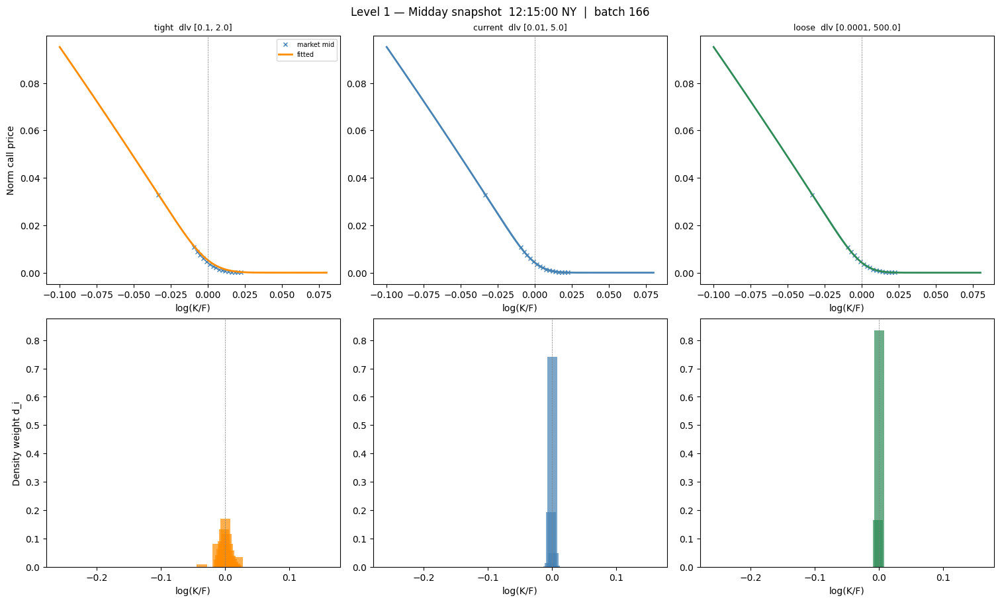

In [14]:
# Find batch closest to 12:15 NY time and produce 2×3 figure:
# top row = price smiles, bottom row = density bars. Shared y-axis per row.


def _hours(ts):
    return ts.hour + ts.minute / 60.0 + ts.second / 3600.0


midday_idx = min(range(len(results)), key=lambda i: abs(_hours(results[i]["ts"]) - 12.25))
r_mid = results[midday_idx]
ts_mid = r_mid["ts"]

snap_c_mid = snaps_calls.filter(pl.col("batch_ts") == ts_mid).sort("pure_strike")
snap_p_mid = snaps_puts.filter(pl.col("batch_ts") == ts_mid).sort("pure_strike")
tte_mid = float(snap_c_mid["T"].median()) if not snap_c_mid.is_empty() else tte_y_med
print(f"Midday batch: {ts_mid}  (idx {midday_idx + 1}/{len(results)})")

lk_dense = np.linspace(-0.10, 0.08, 150)
pk_dense = np.exp(lk_dense)
tte_dense = np.full(150, tte_mid)

cfg_names_l = list(DLV_CONFIGS.keys())
n_cfg = len(cfg_names_l)

# Pre-compute fitted curves and density bars per config (calls)
fitted_mid = {}
dens_mid = {}
for cfg_name in cfg_names_l:
    pricer_c = dlv_sanos[cfg_name]["c"]
    dlvsqs_c = r_mid.get(f"dlv_{cfg_name}_dlvsqs_c")
    fwdvols_r = r_mid.get(f"dlv_{cfg_name}_fwdvols_c")
    if dlvsqs_c is None:
        fitted_mid[cfg_name] = dens_mid[cfg_name] = None
        continue
    try:
        dens_list = r_mid.get(f"dlv_{cfg_name}_densities_c")
        if dens_list is None:
            fitted_mid[cfg_name] = dens_mid[cfg_name] = None
            continue
        curve = pricer_c.price(
            fwdvols_r,
            dens_list,
            opt_strikes=pk_dense,
            opt_tte=tte_dense,
            opt_is_call=np.ones(150, dtype=bool),
            opt_mask=np.ones(150, dtype=bool),
        )
        fitted_mid[cfg_name] = curve
        strk_inner = np.asarray(pricer_c.geometry.xstrikes[1])[1:-1]
        dens_mid[cfg_name] = (np.log(strk_inner), np.asarray(dens_list[0]))
    except Exception as e:
        print(f"  {cfg_name}: {e}")
        fitted_mid[cfg_name] = dens_mid[cfg_name] = None

# Market bid-ask (calls)
lk_c_m = np.log(snap_c_mid["pure_strike"].to_numpy())
bid_c_m = snap_c_mid["bid_norm"].to_numpy()
ask_c_m = snap_c_mid["ask_norm"].to_numpy()

fig, axes = plt.subplots(2, n_cfg, figsize=(5 * n_cfg, 9), constrained_layout=True)
fig.suptitle(
    f"Level 1 — Midday snapshot  {ts_mid.strftime('%H:%M:%S')} NY  |  batch {midday_idx + 1}",
    fontsize=12,
)

for j, cfg_name in enumerate(cfg_names_l):
    ax_sm = axes[0, j]
    ax_dn = axes[1, j]
    clr = CFG_COLORS[cfg_name]
    cfg_p = DLV_CONFIGS[cfg_name]

    # Price smile
    ax_sm.fill_between(lk_c_m, bid_c_m, ask_c_m, alpha=0.25, color="steelblue")
    ax_sm.plot(lk_c_m, (bid_c_m + ask_c_m) / 2, "x", color="steelblue", ms=5, label="market mid")
    if fitted_mid[cfg_name] is not None:
        ax_sm.plot(lk_dense, fitted_mid[cfg_name], color=clr, lw=2, label="fitted")
    ax_sm.axvline(0, color="gray", lw=0.5, ls="--")
    ax_sm.set_title(f"{cfg_name}  dlv [{cfg_p['dlv_min']}, {cfg_p['dlv_max']}]", fontsize=9)
    ax_sm.set_xlabel("log(K/F)")
    if j == 0:
        ax_sm.set_ylabel("Norm call price")
        ax_sm.legend(fontsize=7)

    # Density bars
    if dens_mid[cfg_name] is not None:
        lk_dn, d_vals = dens_mid[cfg_name]
        bw = np.diff(lk_dn).mean() * 0.7 if len(lk_dn) > 1 else 0.02
        ax_dn.bar(lk_dn, d_vals, width=bw, color=clr, alpha=0.7)
    ax_dn.axvline(0, color="gray", lw=0.5, ls="--")
    ax_dn.set_xlabel("log(K/F)")
    if j == 0:
        ax_dn.set_ylabel("Density weight d_i")

# Shared y-axis ranges within each row
for row_axes in [axes[0], axes[1]]:
    ymin = min(ax.get_ylim()[0] for ax in row_axes)
    ymax = max(ax.get_ylim()[1] for ax in row_axes)
    for ax in row_axes:
        ax.set_ylim(ymin, ymax)

plt.show()

## Level 2 — Per-batch in-sample metrics

For each batch × DLV config (calls side):
- **Fit quality**: weighted MSE on mids (w = 1/half-spread²), band-violation count, band-violation magnitude in half-spread units.
- **Density shape**: entropy (higher = more spread out), effective support (nodes with d > 0.001), boundary mass d₀ + d₋₁, max single-node mass.
- **Binding constraint rate**: fraction of inner nodes where DLV² touches dlv_min² or dlv_max².


In [15]:
# Per-batch in-sample metrics for all three DLV configs (calls side).
# For each batch × config: weighted MSE, band violations, density shape, binding rate.

batch_metrics = []
for batch_idx, r in enumerate(tqdm(results, desc="Batch metrics")):
    ts = r["ts"]
    snap_c = snaps_calls.filter(pl.col("batch_ts") == ts).sort("pure_strike")
    if snap_c.is_empty():
        continue

    pk_b = snap_c["pure_strike"].to_numpy().astype(float)
    bid_b = snap_c["bid_norm"].to_numpy().astype(float)
    ask_b = snap_c["ask_norm"].to_numpy().astype(float)
    mid_b = (bid_b + ask_b) / 2
    hs_b = (ask_b - bid_b) / 2
    tte_b = float(snap_c["T"].median())
    tte_arr = np.full(len(pk_b), tte_b)
    ts_h = ts.hour + ts.minute / 60.0 + ts.second / 3600.0

    for cfg_name in DLV_CONFIGS:
        dlvsqs_c = r.get(f"dlv_{cfg_name}_dlvsqs_c")
        fwdvols_r = r.get(f"dlv_{cfg_name}_fwdvols_c")
        if dlvsqs_c is None:
            continue
        pricer_c = dlv_sanos[cfg_name]["c"]
        dens_list = r.get(f"dlv_{cfg_name}_densities_c")
        if dens_list is None:
            continue
        if batch_idx == 0:
            print(batch_idx, float(dens_list[0][5]))
        try:
            fit_b = pricer_c.price(
                fwdvols_r,
                dens_list,
                opt_strikes=pk_b,
                opt_tte=tte_arr,
                opt_is_call=np.ones(len(pk_b), dtype=bool),
                opt_mask=np.ones(len(pk_b), dtype=bool),
            )
        except Exception:
            continue

        ok = np.isfinite(fit_b) & np.isfinite(mid_b) & (hs_b > 0)
        if ok.sum() == 0:
            continue

        # Fit quality
        w = 1.0 / hs_b[ok] ** 2
        wmse = float(np.sum(w * (fit_b[ok] - mid_b[ok]) ** 2) / np.sum(w))
        viol_count = int(np.sum((fit_b < bid_b) | (fit_b > ask_b)))
        mean_hs = float(hs_b[hs_b > 0].mean())
        viol_mag = float(
            np.sum(np.maximum(0, fit_b - ask_b) + np.maximum(0, bid_b - fit_b)) / mean_hs
        )

        # Density shape
        d = np.asarray(dens_list[0])
        d_pos = np.where(d > 0, d, 1e-15)
        ent = float(-np.sum(d * np.log(d_pos)))
        eff_supp = int(np.sum(d > 0.001))
        bdy_mass = float(d[0] + d[-1])
        max_mass = float(np.max(d))

        # Binding constraint rate: nodes where DLV² is at its bound
        cfg_p = DLV_CONFIGS[cfg_name]
        dmin2, dmax2 = cfg_p["dlv_min"] ** 2, cfg_p["dlv_max"] ** 2
        # dlvsqs_c values are net of dlv_min², so they live in [0, dmax2-dmin2].
        dq = np.asarray(dlvsqs_c).ravel()
        net_max = dmax2 - dmin2
        tol = max(net_max * 1e-4, 1e-10)
        n_bind = int(np.sum((dq <= tol) | (dq >= net_max - tol)))
        binding_rate = n_bind / max(len(dq), 1)

        batch_metrics.append(
            {
                "batch_idx": batch_idx,
                "ts_h": ts_h,
                "config": cfg_name,
                "wmse": wmse,
                "viol_count": viol_count,
                "viol_mag": viol_mag,
                "entropy": ent,
                "eff_support": float(eff_supp),
                "boundary_mass": bdy_mass,
                "max_mass": max_mass,
                "binding_rate": binding_rate,
            }
        )

df_metrics = pl.DataFrame(batch_metrics)
print(
    f"df_metrics: {df_metrics.shape[0]} rows  "
    f"(~{df_metrics.shape[0] // max(len(DLV_CONFIGS), 1)} batches × {len(DLV_CONFIGS)} configs)"
)
for cfg_name in DLV_CONFIGS:
    sub = df_metrics.filter(pl.col("config") == cfg_name)
    print(f"\n{cfg_name}:")
    for col in ["wmse", "viol_count", "binding_rate", "entropy", "boundary_mass"]:
        arr = sub[col].to_numpy()
        print(
            f"  {col:18s}: mean={np.mean(arr):.4f}  median={np.median(arr):.4f}  "
            f"p95={np.percentile(arr, 95):.4f}"
        )

0 0.06237299621881997
0 0.0008442608445052185
0 9.43269710934236e-12
df_metrics: 1214 rows  (~404 batches × 3 configs)

tight:
  wmse              : mean=0.0000  median=0.0000  p95=0.0000
  viol_count        : mean=15.4321  median=16.0000  p95=16.0000
  binding_rate      : mean=1.0000  median=1.0000  p95=1.0000
  entropy           : mean=2.5366  median=2.5366  p95=2.5366
  boundary_mass     : mean=0.0001  median=0.0001  p95=0.0001

current:
  wmse              : mean=0.0000  median=0.0000  p95=0.0000
  viol_count        : mean=12.4642  median=13.0000  p95=15.0000
  binding_rate      : mean=1.0000  median=1.0000  p95=1.0000
  entropy           : mean=0.7713  median=0.7713  p95=0.7713
  boundary_mass     : mean=0.0000  median=0.0000  p95=0.0000

loose:
  wmse              : mean=0.0000  median=0.0000  p95=0.0000
  viol_count        : mean=12.7203  median=13.0000  p95=15.0000
  binding_rate      : mean=0.9978  median=1.0000  p95=1.0000
  entropy           : mean=0.4489  median=0.4489  p95

In [16]:
# # Expose the hidden exception
# r0 = results[0]
# row0 = df_t_front.row(0, named=True)
# is_call = row0["is_call"]
# log_k = row0["log_moneyness"]
# tte = row0["T"]
# fwd = row0["forward"]
# df_ = row0["discount_factor"]
# pure_k = float(np.exp(log_k))
# side = "c" if is_call else "p"

# print(f"is_call={is_call}, pure_k={pure_k:.4f}, tte={tte:.6f}")
# print(f"fwdvols_c={r0['grid_fwdvols_c']}")

# for gname, pricer in [
#     ("grid", grid_sanos_c if is_call else grid_sanos_p),
#     ("open", open_sanos_c if is_call else open_sanos_p),
# ]:
#     dlvsqs = r0.get(f"{gname}_dlvsqs_{side}")
#     fwdvols = r0.get(f"{gname}_fwdvols_{side}")
#     print(f"\n{gname}: dlvsqs.shape={np.asarray(dlvsqs).shape}")
#     dens = pricer.densities(dlvsqs)
#     print(f"  densities OK")
#     result = pricer.price(
#         fwdvols,
#         dens,
#         opt_strikes=np.array([pure_k]),
#         opt_tte=np.array([tte]),
#         opt_is_call=np.array([is_call]),
#     )
#     print(f"  price = {result}")


## Evaluate fitted prices on out-of-sample trades

For each trade, find the nearest **preceding** fit (by timestamp) via binary search, then price the trade strike with that fit.

In [17]:
# === DIAGNOSTICS ===
print(f"results count: {len(results)}")
print(f"n_failed: {n_failed}")
if results:
    r0 = results[0]
    print(f"First result keys: {list(r0.keys())}")
    for gname in ["grid", "open"]:
        for side in ["c", "p"]:
            v = r0.get(f"{gname}_dlvsqs_{side}")
            print(
                f"  {gname}_dlvsqs_{side}: {'None' if v is None else 'OK shape ' + str(np.asarray(v).shape)}"
            )
    _fit_ts = [r["ts"] for r in results]
    _ts0 = df_t_front.row(0, named=True)["ts_ns"]
    _idx = bisect.bisect_right(_fit_ts, _ts0) - 1
    print(f"First trade ts: {_ts0}  (type {type(_ts0).__name__})")
    print(f"First fit ts:   {_fit_ts[0]}  (type {type(_fit_ts[0]).__name__})")
    print(f"bisect idx for first trade: {_idx}")
else:
    print("WARNING: results is empty")
# ==================

results count: 405
n_failed: {'grid_c': 0, 'grid_p': 0, 'open_c': 0, 'open_p': 0, 'dlv_tight_c': 0, 'dlv_tight_p': 0, 'dlv_current_c': 0, 'dlv_current_p': 0, 'dlv_loose_c': 1, 'dlv_loose_p': 0}
First result keys: ['ts', 'atm_iv_c', 'atm_iv_p', 'n_c', 'n_p', 'grid_dlvsqs_c', 'grid_fwdvols_c', 'grid_dlvsqs_p', 'grid_fwdvols_p', 'open_dlvsqs_c', 'open_fwdvols_c', 'open_dlvsqs_p', 'open_fwdvols_p', 'dlv_tight_dlvsqs_c', 'dlv_tight_densities_c', 'dlv_tight_fwdvols_c', 'dlv_tight_dlvsqs_p', 'dlv_tight_fwdvols_p', 'dlv_current_dlvsqs_c', 'dlv_current_densities_c', 'dlv_current_fwdvols_c', 'dlv_current_dlvsqs_p', 'dlv_current_fwdvols_p', 'dlv_loose_dlvsqs_c', 'dlv_loose_densities_c', 'dlv_loose_fwdvols_c', 'dlv_loose_dlvsqs_p', 'dlv_loose_fwdvols_p']
  grid_dlvsqs_c: OK shape (1, 11)
  grid_dlvsqs_p: OK shape (1, 11)
  open_dlvsqs_c: OK shape (1, 17)
  open_dlvsqs_p: OK shape (1, 21)
First trade ts: 2024-01-03 09:30:00.031000-05:00  (type datetime)
First fit ts:   2024-01-03 09:30:00-05:00  (t

In [18]:
fit_ts_list = [r["ts"] for r in results]  # sorted list of datetime objects


def get_nearest_fit(ts, gname, side):
    idx = bisect.bisect_right(fit_ts_list, ts) - 1
    if idx < 0:
        return None, None
    r = results[idx]
    return r.get(f"{gname}_dlvsqs_{side}"), r.get(f"{gname}_fwdvols_{side}")


def price_single(pricer, dlvsqs, fwdvols, pure_k, tte, is_call):
    dens = pricer.densities(dlvsqs)
    return float(
        pricer.price(
            fwdvols,
            dens,
            opt_strikes=np.array([pure_k]),
            opt_tte=np.array([tte]),
            opt_is_call=np.array([is_call]),
            opt_mask=np.ones(1, dtype=bool),
        )[0]
    )


trade_evals = []
for row in df_t_front.iter_rows(named=True):
    ts = row["ts_ns"]
    is_call = row["is_call"]
    log_k = row["log_moneyness"]
    tte = row["T"]
    fwd = row["forward"]
    df_ = row["discount_factor"]
    obs_price = row["observed_price"]
    bid_q = row.get("bid_price", float("nan"))
    ask_q = row.get("ask_price", float("nan"))

    if not (np.isfinite(obs_price) and obs_price > 0 and np.isfinite(log_k)):
        continue

    scale = fwd * df_
    pure_k_f = float(np.exp(log_k))
    obs_norm = obs_price / scale
    side = "c" if is_call else "p"
    half_sp = (
        (ask_q - bid_q) / 2
        if (np.isfinite(bid_q) and np.isfinite(ask_q) and ask_q > bid_q)
        else float("nan")
    )
    obs_iv = (
        sanos_option._iv_from_norm_call(obs_norm, float(log_k), float(tte))
        if is_call
        else sanos_option._iv_from_norm_put(obs_norm, float(log_k), float(tte))
    )

    erow = {
        "ts_ns": ts,
        "is_call": is_call,
        "log_k": log_k,
        "tte": tte,
        "obs_price": obs_price,
        "half_sp": half_sp,
        "obs_iv": obs_iv,
    }

    # Grid + Open configs
    for gname, pricer in [
        ("grid", grid_sanos_c if is_call else grid_sanos_p),
        ("open", open_sanos_c if is_call else open_sanos_p),
    ]:
        dlvsqs, fwdvols = get_nearest_fit(ts, gname, side)
        if dlvsqs is None:
            continue
        try:
            fit_norm = price_single(pricer, dlvsqs, fwdvols, pure_k_f, float(tte), is_call)
            if not (np.isfinite(fit_norm) and fit_norm > 0):
                continue
            fit_price = fit_norm * scale
            pe_norm = (
                (fit_price - obs_price) / half_sp
                if np.isfinite(half_sp) and half_sp > 0
                else float("nan")
            )
            fit_iv = (
                sanos_option._iv_from_norm_call(fit_norm, float(log_k), float(tte))
                if is_call
                else sanos_option._iv_from_norm_put(fit_norm, float(log_k), float(tte))
            )
            iv_err = (
                (fit_iv - obs_iv) if np.isfinite(obs_iv) and np.isfinite(fit_iv) else float("nan")
            )
            erow[f"{gname}_fit_norm"] = fit_norm
            erow[f"{gname}_price_err"] = pe_norm
            erow[f"{gname}_iv_err"] = iv_err
        except Exception:
            pass

    # DLV bound configs
    for cfg_name in DLV_CONFIGS:
        gname = f"dlv_{cfg_name}"
        pricer = dlv_sanos[cfg_name]["c" if is_call else "p"]
        dlvsqs, fwdvols = get_nearest_fit(ts, gname, side)
        if dlvsqs is None:
            continue
        try:
            fit_norm = price_single(pricer, dlvsqs, fwdvols, pure_k_f, float(tte), is_call)
            if not (np.isfinite(fit_norm) and fit_norm > 0):
                continue
            fit_price = fit_norm * scale
            pe_norm = (
                (fit_price - obs_price) / half_sp
                if np.isfinite(half_sp) and half_sp > 0
                else float("nan")
            )
            fit_iv = (
                sanos_option._iv_from_norm_call(fit_norm, float(log_k), float(tte))
                if is_call
                else sanos_option._iv_from_norm_put(fit_norm, float(log_k), float(tte))
            )
            iv_err = (
                (fit_iv - obs_iv) if np.isfinite(obs_iv) and np.isfinite(fit_iv) else float("nan")
            )
            erow[f"{gname}_fit_norm"] = fit_norm
            erow[f"{gname}_price_err"] = pe_norm
            erow[f"{gname}_iv_err"] = iv_err
        except Exception:
            pass

    trade_evals.append(erow)

df_evals = pl.DataFrame(trade_evals)
print(f"Evaluated {len(df_evals):,} trades")
df_evals.head(3)

Evaluated 74,099 trades


ts_ns,is_call,log_k,tte,obs_price,half_sp,obs_iv,grid_fit_norm,grid_price_err,grid_iv_err,open_fit_norm,open_price_err,open_iv_err,dlv_tight_fit_norm,dlv_tight_price_err,dlv_tight_iv_err,dlv_current_fit_norm,dlv_current_price_err,dlv_current_iv_err,dlv_loose_fit_norm,dlv_loose_price_err,dlv_loose_iv_err
"datetime[μs, America/New_York]",bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.031 EST,true,0.01799,0.006217,0.08,0.025,0.130704,0.000212,0.784008,0.00565,0.000214,0.833607,0.005986,0.000576,7.646439,0.04035,0.000214,0.833607,0.005986,0.000211,0.773632,0.00558
2024-01-03 09:30:00.051 EST,true,0.020075,0.006217,0.08,0.005,0.142889,0.000131,-3.70274,-0.00653,0.000133,-3.530008,-0.006201,0.000416,23.178351,0.02878,0.000133,-3.530008,-0.006201,0.00013,-3.743747,-0.006608
2024-01-03 09:30:00.102 EST,false,-0.016005,0.006217,0.25,0.005,0.154283,0.000464,-6.303176,-0.005258,0.000486,-4.247444,-0.003507,0.000799,25.178496,0.018545,0.000486,-4.247444,-0.003507,0.000488,-4.095101,-0.003379


In [19]:
df_evals

ts_ns,is_call,log_k,tte,obs_price,half_sp,obs_iv,grid_fit_norm,grid_price_err,grid_iv_err,open_fit_norm,open_price_err,open_iv_err,dlv_tight_fit_norm,dlv_tight_price_err,dlv_tight_iv_err,dlv_current_fit_norm,dlv_current_price_err,dlv_current_iv_err,dlv_loose_fit_norm,dlv_loose_price_err,dlv_loose_iv_err
"datetime[μs, America/New_York]",bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.031 EST,true,0.01799,0.006217,0.08,0.025,0.130704,0.000212,0.784008,0.00565,0.000214,0.833607,0.005986,0.000576,7.646439,0.04035,0.000214,0.833607,0.005986,0.000211,0.773632,0.00558
2024-01-03 09:30:00.051 EST,true,0.020075,0.006217,0.08,0.005,0.142889,0.000131,-3.70274,-0.00653,0.000133,-3.530008,-0.006201,0.000416,23.178351,0.02878,0.000133,-3.530008,-0.006201,0.00013,-3.743747,-0.006608
2024-01-03 09:30:00.102 EST,false,-0.016005,0.006217,0.25,0.005,0.154283,0.000464,-6.303176,-0.005258,0.000486,-4.247444,-0.003507,0.000799,25.178496,0.018545,0.000486,-4.247444,-0.003507,0.000488,-4.095101,-0.003379
2024-01-03 09:30:00.102 EST,false,-0.009547,0.006217,0.57,0.01,0.141628,0.00128,3.243362,0.003148,0.001269,2.710419,0.002634,0.00188,31.453846,0.028912,0.001269,2.710419,0.002634,0.001268,2.650721,0.002577
2024-01-03 09:30:00.111 EST,true,0.003279,0.006217,1.47,0.07,0.145379,0.002852,-1.833238,-0.009043,0.002863,-1.758103,-0.008672,0.003829,4.734381,0.023161,0.002863,-1.758103,-0.008672,0.002851,-1.839197,-0.009073
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:55.650 EST,false,-0.004385,0.005447,1.04,0.005,0.137432,0.002268,4.369776,0.001742,0.002251,2.735368,0.001091,0.003153,87.217401,0.034171,0.002251,2.735368,0.001091,0.002243,2.008136,0.000801
2024-01-03 16:14:56.139 EST,false,-0.002252,0.005447,1.4,0.01,0.136321,0.003053,3.189891,0.00237,0.003033,2.285718,0.001698,0.003988,47.058129,0.034799,0.003033,2.285718,0.001698,0.003025,1.868866,0.001389
2024-01-03 16:14:56.139 EST,false,-0.002252,0.005447,1.4,0.01,0.136321,0.003053,3.189891,0.00237,0.003033,2.285718,0.001698,0.003988,47.058129,0.034799,0.003033,2.285718,0.001698,0.003025,1.868866,0.001389


## Summary statistics

In [20]:
print(f"df_evals shape: {df_evals.shape}")
print(f"df_evals columns: {df_evals.columns}")
if df_evals.is_empty():
    print(
        "WARNING: df_evals is empty — no trades were evaluated. "
        "Check that results[] is non-empty and fit timestamps overlap trade timestamps."
    )
else:
    print(df_evals.head(3))

print("=" * 64)
for gname in ["grid", "open"]:
    for is_call_v, lbl in [(True, "Calls"), (False, "Puts")]:
        col_pe = f"{gname}_price_err"
        col_iv = f"{gname}_iv_err"
        if col_pe not in df_evals.columns:
            print(
                f"{gname.upper()} {lbl}: column {col_pe!r} missing from df_evals — "
                f"no successful fits were priced on trades"
            )
            continue
        sub = df_evals.filter(
            (pl.col("is_call") == is_call_v)
            & pl.col(col_pe).is_not_null()
            & pl.col(col_pe).is_not_nan()
        )
        if sub.is_empty():
            print(f"{gname.upper()} {lbl}: no data")
            continue
        pe = sub[col_pe].to_numpy().astype(float)
        pe = pe[np.isfinite(pe)]
        print(f"\n{gname.upper()} {lbl}  (n={len(sub):,})")
        if len(pe) > 0:
            print(
                f"  Norm price err: mean={np.mean(pe):.3f}  std={np.std(pe):.3f}  "
                f"|95th|={np.percentile(np.abs(pe), 95):.3f}"
            )
        if col_iv in sub.columns:
            iv = sub[col_iv].to_numpy().astype(float)
            iv = iv[np.isfinite(iv)]
            if len(iv) > 0:
                print(
                    f"  IV error (pct): mean={np.mean(iv) * 100:.2f}  std={np.std(iv) * 100:.2f}  "
                    f"|95th|={np.percentile(np.abs(iv), 95) * 100:.2f}"
                )
print("=" * 64)

df_evals shape: (74099, 22)
df_evals columns: ['ts_ns', 'is_call', 'log_k', 'tte', 'obs_price', 'half_sp', 'obs_iv', 'grid_fit_norm', 'grid_price_err', 'grid_iv_err', 'open_fit_norm', 'open_price_err', 'open_iv_err', 'dlv_tight_fit_norm', 'dlv_tight_price_err', 'dlv_tight_iv_err', 'dlv_current_fit_norm', 'dlv_current_price_err', 'dlv_current_iv_err', 'dlv_loose_fit_norm', 'dlv_loose_price_err', 'dlv_loose_iv_err']
shape: (3, 22)
┌────────────┬─────────┬───────────┬──────────┬───┬────────────┬───────────┬───────────┬───────────┐
│ ts_ns      ┆ is_call ┆ log_k     ┆ tte      ┆ … ┆ dlv_curren ┆ dlv_loose ┆ dlv_loose ┆ dlv_loose │
│ ---        ┆ ---     ┆ ---       ┆ ---      ┆   ┆ t_iv_err   ┆ _fit_norm ┆ _price_er ┆ _iv_err   │
│ datetime[μ ┆ bool    ┆ f64       ┆ f64      ┆   ┆ ---        ┆ ---       ┆ r         ┆ ---       │
│ s, America ┆         ┆           ┆          ┆   ┆ f64        ┆ f64       ┆ ---       ┆ f64       │
│ /New_York] ┆         ┆           ┆          ┆   ┆           

## Level 3A — Aggregate: time-series and distributional view

Left column: each metric plotted over the trading day (scatter + smoothed trend, one line per config). Right column: violin plot of the same metric across all batches with paired Wilcoxon signed-rank p-values. Pairing is by `batch_idx` so batch-level variation in quote quality is controlled out. Look for where the configs diverge in time (open vs midday) and whether differences are statistically significant.


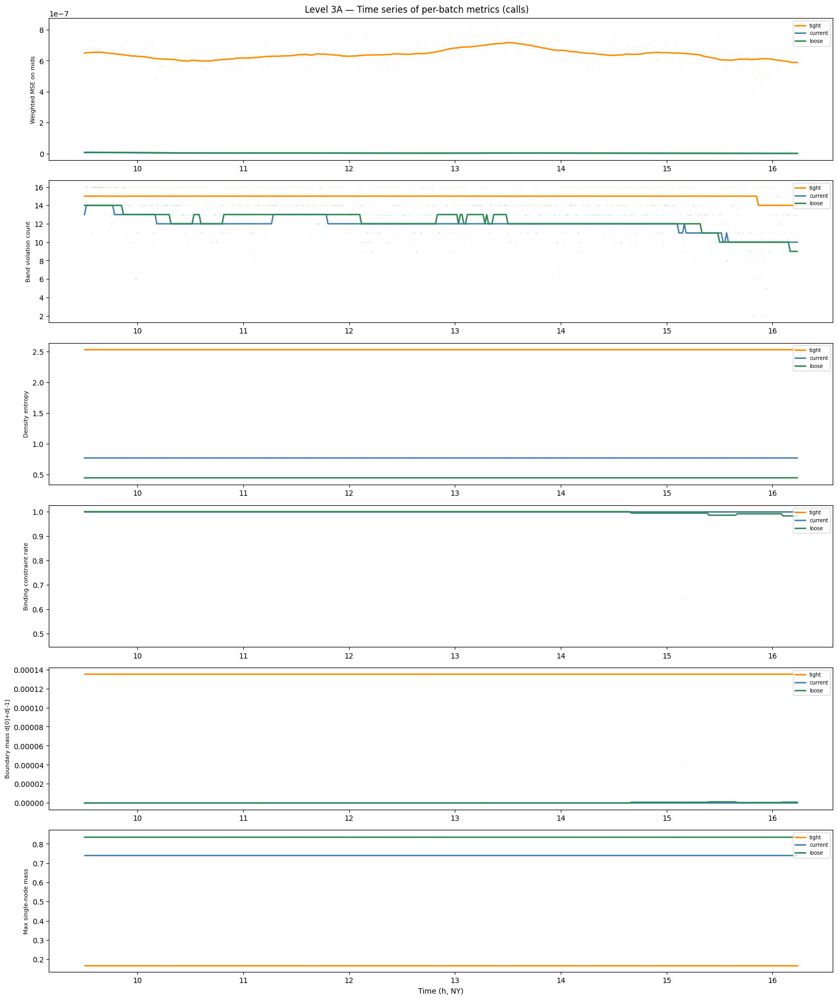

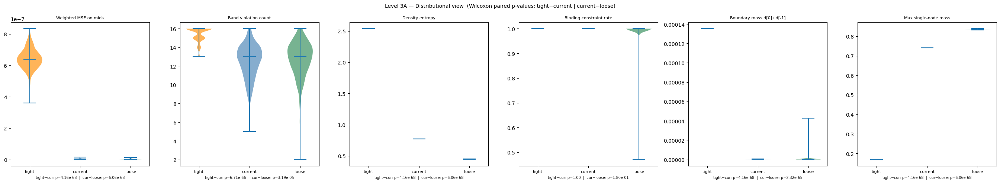

In [21]:
from scipy import stats as scipy_stats
from scipy.ndimage import uniform_filter1d

metrics_to_plot = [
    ("wmse", "Weighted MSE on mids"),
    ("viol_count", "Band violation count"),
    ("entropy", "Density entropy"),
    ("binding_rate", "Binding constraint rate"),
    ("boundary_mass", "Boundary mass d[0]+d[-1]"),
    ("max_mass", "Max single-node mass"),
]
cfg_names_l = list(DLV_CONFIGS.keys())
n_cfg = len(cfg_names_l)
n_m = len(metrics_to_plot)

# Pivot: per-config arrays aligned by batch_idx
pivot = {}
for cfg_name in cfg_names_l:
    sub = df_metrics.filter(pl.col("config") == cfg_name).sort("batch_idx")
    pivot[cfg_name] = {
        "batch_idx": sub["batch_idx"].to_numpy(),
        "ts_h": sub["ts_h"].to_numpy(),
        **{col: sub[col].to_numpy() for col, _ in metrics_to_plot},
    }

fig_ts, axes_ts = plt.subplots(n_m, 1, figsize=(16, 3.2 * n_m), squeeze=False)
fig_ts.suptitle("Level 3A — Time series of per-batch metrics (calls)", fontsize=12)

fig_vl, axes_vl = plt.subplots(1, n_m, figsize=(4.5 * n_m, 5), squeeze=False)
fig_vl.suptitle(
    "Level 3A — Distributional view  (Wilcoxon paired p-values: tight−current | current−loose)",
    fontsize=10,
)

for i, (col, label) in enumerate(metrics_to_plot):
    ax_ts = axes_ts[i, 0]
    ax_vl = axes_vl[0, i]
    bp_data = []

    for cfg_name in cfg_names_l:
        ts_h_arr = pivot[cfg_name]["ts_h"]
        vals = pivot[cfg_name][col]
        bp_data.append(vals)
        clr = CFG_COLORS[cfg_name]
        ax_ts.scatter(ts_h_arr, vals, s=1, alpha=0.10, color=clr)
        srt = np.argsort(ts_h_arr)
        smooth = uniform_filter1d(vals[srt], size=min(60, len(vals)))
        ax_ts.plot(ts_h_arr[srt], smooth, lw=2, color=clr, label=cfg_name)

    ax_ts.set_ylabel(label, fontsize=8)
    ax_ts.legend(fontsize=7, loc="upper right")
    if i == n_m - 1:
        ax_ts.set_xlabel("Time (h, NY)")

    # Violin plot
    parts = ax_vl.violinplot(bp_data, positions=range(n_cfg), showmedians=True)
    for pc, cfg_name in zip(parts["bodies"], cfg_names_l):
        pc.set_facecolor(CFG_COLORS[cfg_name])
        pc.set_alpha(0.65)
    ax_vl.set_xticks(range(n_cfg))
    ax_vl.set_xticklabels(cfg_names_l, fontsize=8)
    ax_vl.set_title(label, fontsize=8)

    # Paired Wilcoxon (tight vs current, current vs loose)
    p_labels = []
    for cfg_a, cfg_b in [("tight", "current"), ("current", "loose")]:
        a_idx, b_idx = pivot[cfg_a]["batch_idx"], pivot[cfg_b]["batch_idx"]
        common = np.intersect1d(a_idx, b_idx)
        if len(common) < 10:
            p_labels.append("n/a")
            continue
        a_v = pivot[cfg_a][col][np.isin(a_idx, common)]
        b_v = pivot[cfg_b][col][np.isin(b_idx, common)]
        diff = a_v - b_v
        if np.all(diff == 0):
            p_labels.append("p=1.00")
        else:
            _, pval = scipy_stats.wilcoxon(diff, zero_method="wilcox")
            p_labels.append(f"p={pval:.2e}")
    ax_vl.set_xlabel(f"tight−cur: {p_labels[0]}  |  cur−loose: {p_labels[1]}", fontsize=7)

fig_ts.tight_layout()
fig_vl.tight_layout()
plt.show()

## Level 3B — Out-of-sample trade evaluation per DLV config

The most important test: evaluate the 74k actual trades against the nearest preceding fit for each DLV config. Lower MAE = better generalization. Bias (signed mean) reveals systematic over/underpricing. All three configs are evaluated identically so differences are attributable solely to DLV bounds.


Level 3B — Out-of-sample error per DLV config

TIGHT Calls  (n=35,057)
  |PE| MAE=79.793  bias=79.793  |95th|=103.113  half-spreads
  IV  MAE=3.56 vpts  bias=3.56 vpts

TIGHT Puts  (n=39,017)
  |PE| MAE=69.242  bias=69.238  |95th|=98.304  half-spreads
  IV  MAE=3.14 vpts  bias=3.14 vpts

CURRENT Calls  (n=35,057)
  |PE| MAE=4.536  bias=3.953  |95th|=10.830  half-spreads
  IV  MAE=0.23 vpts  bias=0.16 vpts

CURRENT Puts  (n=39,017)
  |PE| MAE=3.921  bias=3.295  |95th|=9.097  half-spreads
  IV  MAE=0.20 vpts  bias=0.12 vpts

LOOSE Calls  (n=34,866)
  |PE| MAE=3.930  bias=3.038  |95th|=9.894  half-spreads
  IV  MAE=0.20 vpts  bias=0.12 vpts

LOOSE Puts  (n=39,017)
  |PE| MAE=3.529  bias=2.857  |95th|=8.447  half-spreads
  IV  MAE=0.19 vpts  bias=0.10 vpts


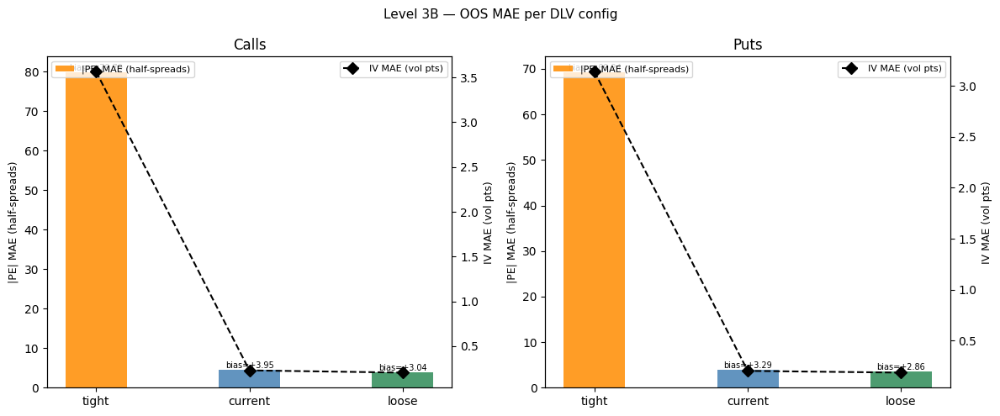

In [22]:
# Level 3B — OOS per-DLV-config comparison
print("Level 3B — Out-of-sample error per DLV config")
print("=" * 70)

oos_rows = []
for cfg_name in DLV_CONFIGS:
    pe_col = f"dlv_{cfg_name}_price_err"
    iv_col = f"dlv_{cfg_name}_iv_err"
    if pe_col not in df_evals.columns:
        print(f"  {cfg_name}: OOS columns missing — re-run the OOS cell after refitting")
        continue
    for is_call_v, lbl in [(True, "Calls"), (False, "Puts")]:
        sub = df_evals.filter(
            (pl.col("is_call") == is_call_v)
            & pl.col(pe_col).is_not_null()
            & pl.col(pe_col).is_not_nan()
        )
        if sub.is_empty():
            continue
        pe = sub[pe_col].to_numpy().astype(float)
        pe = pe[np.isfinite(pe)]
        iv = sub[iv_col].to_numpy().astype(float) if iv_col in sub.columns else np.array([])
        iv = iv[np.isfinite(iv)]
        row_oos = {
            "config": cfg_name,
            "side": lbl,
            "n": len(pe),
            "mae_price": float(np.mean(np.abs(pe))) if len(pe) > 0 else float("nan"),
            "bias_price": float(np.mean(pe)) if len(pe) > 0 else float("nan"),
            "p95_price": float(np.percentile(np.abs(pe), 95)) if len(pe) > 0 else float("nan"),
            "mae_iv_vpts": float(np.mean(np.abs(iv)) * 100) if len(iv) > 0 else float("nan"),
            "bias_iv_vpts": float(np.mean(iv) * 100) if len(iv) > 0 else float("nan"),
        }
        oos_rows.append(row_oos)
        print(f"\n{cfg_name.upper()} {lbl}  (n={row_oos['n']:,})")
        print(
            f"  |PE| MAE={row_oos['mae_price']:.3f}  bias={row_oos['bias_price']:.3f}  "
            f"|95th|={row_oos['p95_price']:.3f}  half-spreads"
        )
        print(
            f"  IV  MAE={row_oos['mae_iv_vpts']:.2f} vpts  bias={row_oos['bias_iv_vpts']:.2f} vpts"
        )

print("=" * 70)
df_oos = pl.DataFrame(oos_rows)

# Bar chart: |PE| MAE per config, IV MAE on right axis
fig, axes_oos = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Level 3B — OOS MAE per DLV config", fontsize=11)

for ax, side in zip(axes_oos, ["Calls", "Puts"]):
    sub_oos = df_oos.filter(pl.col("side") == side)
    if sub_oos.is_empty():
        ax.set_visible(False)
        continue
    cfgs_oos = sub_oos["config"].to_list()
    mae_pe = sub_oos["mae_price"].to_numpy()
    mae_iv = sub_oos["mae_iv_vpts"].to_numpy()
    bias_pe = sub_oos["bias_price"].to_numpy()
    x = np.arange(len(cfgs_oos))
    bars = ax.bar(
        x,
        mae_pe,
        width=0.4,
        color=[CFG_COLORS[c] for c in cfgs_oos],
        alpha=0.85,
        label="|PE| MAE (half-spreads)",
    )
    for bar, bp in zip(bars, bias_pe):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.02,
            f"bias={bp:+.2f}",
            ha="center",
            va="bottom",
            fontsize=7,
        )
    ax_r = ax.twinx()
    ax_r.plot(x, mae_iv, "D--", color="black", ms=7, label="IV MAE (vol pts)")
    ax_r.set_ylabel("IV MAE (vol pts)", fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(cfgs_oos)
    ax.set_ylabel("|PE| MAE (half-spreads)", fontsize=9)
    ax.set_title(side)
    ax.legend(loc="upper left", fontsize=8)
    ax_r.legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

## Diagnostic — Binding constraint rate

For each batch × DLV config: fraction of inner model nodes where DLV² is at dlv_min² or dlv_max² (within solver tolerance). This is the mechanistic explanation for all other differences between configs. High binding rate + worse OOS → bounds are biasing the fit. High binding rate + better OOS → bounds are regularizing. Zero rate for `loose` → it is equivalent to butterfly-arb-only.


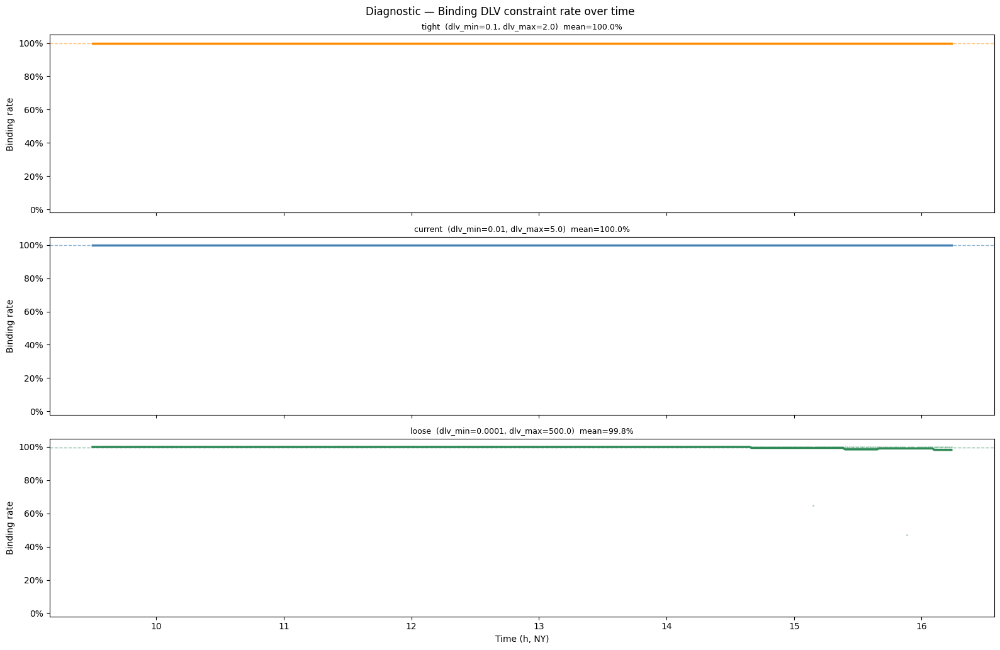


Mean binding rates:
  tight   : 100.0% mean  100.0% median  fraction_batches_>10%: 100.0%
  current : 100.0% mean  100.0% median  fraction_batches_>10%: 100.0%
  loose   : 99.8% mean  100.0% median  fraction_batches_>10%: 100.0%


In [23]:
# Binding constraint rate: fraction of inner DLV² nodes at their bound per batch.
# High rate + worse OOS → bounds are biasing the fit.
# High rate + better OOS → bounds are regularizing toward the truth.
# Zero rate for loose → it is equivalent to butterfly-arb-only.

if df_metrics.is_empty():
    print("Run the Level 2 cell first to compute df_metrics.")
else:
    from scipy.ndimage import uniform_filter1d as _ufi

    cfg_names_l = list(DLV_CONFIGS.keys())
    n_cfg = len(cfg_names_l)

    fig, axes_b = plt.subplots(n_cfg, 1, figsize=(16, 3.5 * n_cfg), sharex=True)
    fig.suptitle("Diagnostic — Binding DLV constraint rate over time", fontsize=12)

    for ax, cfg_name in zip(axes_b, DLV_CONFIGS.keys()):
        sub = df_metrics.filter(pl.col("config") == cfg_name).sort("ts_h")
        ts_h_arr = sub["ts_h"].to_numpy()
        br = sub["binding_rate"].to_numpy()
        clr = CFG_COLORS[cfg_name]
        ax.scatter(ts_h_arr, br, s=2, alpha=0.25, color=clr)
        srt = np.argsort(ts_h_arr)
        smooth = _ufi(br[srt], size=min(60, len(br)))
        ax.plot(ts_h_arr[srt], smooth, lw=2.5, color=clr)
        mean_br = float(np.mean(br))
        ax.axhline(mean_br, color=clr, lw=1, ls="--", alpha=0.6)
        cfg_p = DLV_CONFIGS[cfg_name]
        ax.set_ylabel("Binding rate")
        ax.set_title(
            f"{cfg_name}  (dlv_min={cfg_p['dlv_min']}, dlv_max={cfg_p['dlv_max']})  "
            f"mean={mean_br:.1%}",
            fontsize=9,
        )
        ax.set_ylim(-0.02, 1.05)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))

    axes_b[-1].set_xlabel("Time (h, NY)")
    plt.tight_layout()
    plt.show()

    print("\nMean binding rates:")
    for cfg_name in DLV_CONFIGS:
        sub = df_metrics.filter(pl.col("config") == cfg_name)
        br = sub["binding_rate"].to_numpy()
        print(
            f"  {cfg_name:8s}: {np.mean(br):.1%} mean  {np.median(br):.1%} median  "
            f"fraction_batches_>10%: {np.mean(br > 0.1):.1%}"
        )

In [24]:
# Expose Open geometry pricing error
r0 = results[0]
row0 = df_t_front.row(0, named=True)
is_call = row0["is_call"]
pure_k = float(np.exp(row0["log_moneyness"]))
tte = row0["T"]
side = "c" if is_call else "p"

pricer = open_sanos_c if is_call else open_sanos_p
dlvsqs = r0[f"open_dlvsqs_{side}"]
fwdvols = r0[f"open_fwdvols_{side}"]

print(f"dlvsqs type={type(dlvsqs)}, len={len(dlvsqs)}, element shape={np.asarray(dlvsqs[0]).shape}")
dens = pricer.densities(dlvsqs)
print(f"densities: len={len(dens)}, shapes={[d.shape for d in dens]}")
print(f"pricer.T={pricer.T}, geometry expiries={pricer.geometry.expiries}")
print(f"opt_tte={tte}, tte_geom={tte_geom}")

result = pricer.price(
    fwdvols,
    dens,
    opt_strikes=np.array([pure_k]),
    opt_tte=np.array([tte]),
    opt_is_call=np.array([is_call]),
    opt_mask=np.ones(1, dtype=bool),
)
print(f"price = {result}")

dlvsqs type=<class 'list'>, len=1, element shape=(17,)
densities: len=1, shapes=[(19,)]
pricer.T=1, geometry expiries=[0.00683892]
opt_tte=0.006217201846781758, tte_geom=0.006838922875659113
price = [0.00021434]


## Fitted vol smiles at N_VIZ timestamps

For each geometry (Grid left, Open right) and option type, shows the SANOS fitted price curve vs market bid-ask at evenly spaced timestamps throughout the day.

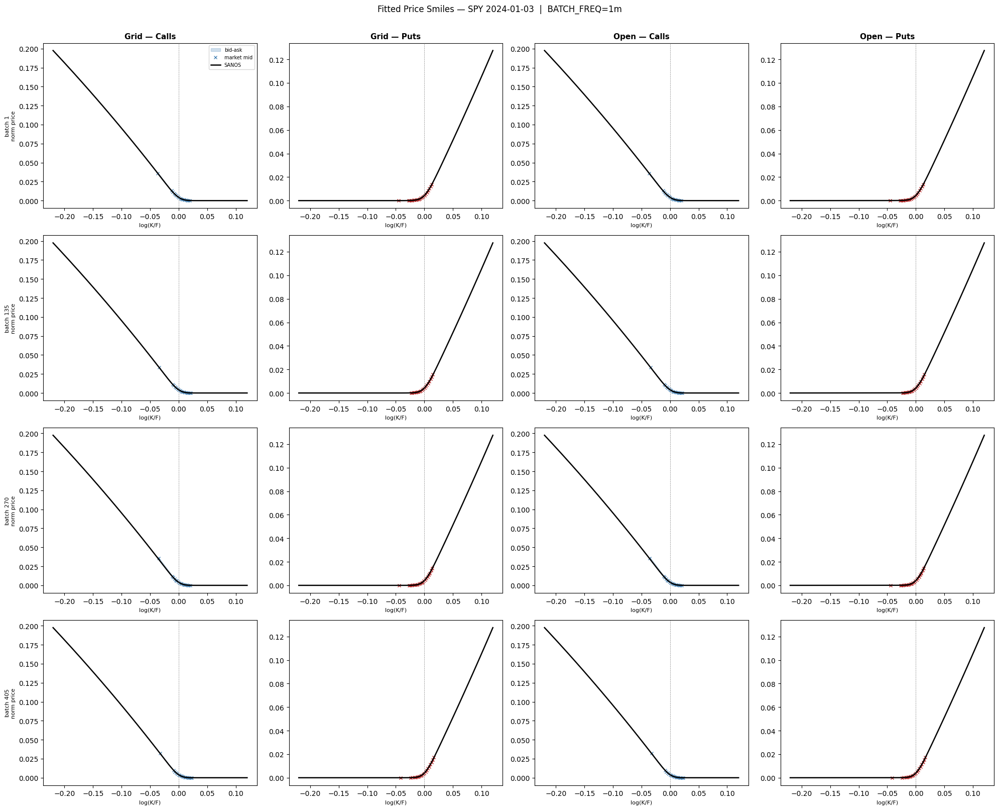

In [25]:
viz_indices = np.linspace(0, len(results) - 1, min(N_VIZ, len(results)), dtype=int)
log_k_dense = np.linspace(-0.22, 0.12, 120)
pk_dense = np.exp(log_k_dense)

nrows = len(viz_indices)
fig, axes = plt.subplots(nrows, 4, figsize=(20, 4 * nrows), squeeze=False)
col_labels = ["Grid — Calls", "Grid — Puts", "Open — Calls", "Open — Puts"]
for j, lbl in enumerate(col_labels):
    axes[0, j].set_title(lbl, fontsize=11, fontweight="bold")

primer_map = {
    "grid_c": grid_sanos_c,
    "grid_p": grid_sanos_p,
    "open_c": open_sanos_c,
    "open_p": open_sanos_p,
}

for i, res_idx in enumerate(viz_indices):
    r = results[int(res_idx)]
    ts_sel = r["ts"]
    snap_c = snaps_calls.filter(pl.col("batch_ts") == ts_sel).sort("pure_strike")
    snap_p = snaps_puts.filter(pl.col("batch_ts") == ts_sel).sort("pure_strike")
    tte_sn = float(snap_c["T"].median()) if not snap_c.is_empty() else tte_y_med
    tte_arr = np.full(len(pk_dense), tte_sn)

    for j, (gname, side, is_call_p, snap, clr) in enumerate(
        [
            ("grid", "c", True, snap_c, "steelblue"),
            ("grid", "p", False, snap_p, "firebrick"),
            ("open", "c", True, snap_c, "steelblue"),
            ("open", "p", False, snap_p, "firebrick"),
        ]
    ):
        ax = axes[i, j]
        pricer = primer_map[f"{gname}_{side}"]

        if not snap.is_empty():
            lk_mkt = np.log(snap["pure_strike"].to_numpy())
            bids = snap["bid_norm"].to_numpy()
            asks = snap["ask_norm"].to_numpy()
            ax.fill_between(lk_mkt, bids, asks, alpha=0.25, color=clr, label="bid-ask")
            ax.plot(lk_mkt, (bids + asks) / 2, "x", color=clr, ms=5, label="market mid")

        dlvsqs = r.get(f"{gname}_dlvsqs_{side}")
        fwdvols = r.get(f"{gname}_fwdvols_{side}")
        if dlvsqs is not None:
            try:
                dens = pricer.densities(dlvsqs)
                fitted = pricer.price(
                    fwdvols,
                    dens,
                    opt_strikes=pk_dense,
                    opt_tte=tte_arr,
                    opt_is_call=np.full(len(pk_dense), is_call_p),
                    opt_mask=np.ones(len(pk_dense), dtype=bool),
                )

                ax.plot(log_k_dense, fitted, "-", color="black", lw=1.8, label="SANOS")
            except Exception as ex:
                ax.text(
                    0.5,
                    0.5,
                    str(ex)[:50],
                    transform=ax.transAxes,
                    ha="center",
                    va="center",
                    fontsize=7,
                    color="red",
                )

        ax.axvline(0, color="gray", lw=0.5, ls="--")
        ax.set_xlabel("log(K/F)", fontsize=8)
        if j == 0:
            ax.set_ylabel(f"batch {int(res_idx) + 1}\nnorm price", fontsize=8)
        if i == 0 and j == 0:
            ax.legend(fontsize=7)

fig.suptitle(
    f"Fitted Price Smiles — SPY {TRADE_DATE}  |  BATCH_FREQ={BATCH_FREQ}", fontsize=12, y=1.005
)
plt.tight_layout()
plt.show()

## Error metrics over time

Normalized price error = (fitted − trade) / half-spread.  
IV error = fitted IV − trade IV (in vol-point percentage).

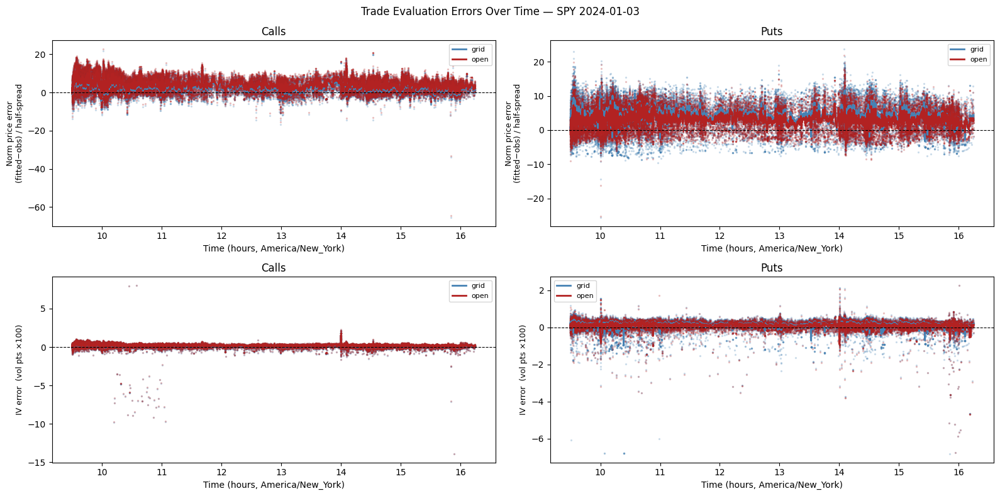

In [26]:
from scipy.ndimage import uniform_filter1d

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
fig.suptitle(f"Trade Evaluation Errors Over Time — SPY {TRADE_DATE}", fontsize=12)

for col_idx, is_call_v in enumerate([True, False]):
    ltype = "Calls" if is_call_v else "Puts"
    sub = df_evals.filter(pl.col("is_call") == is_call_v)
    if sub.is_empty():
        continue
    # Use dt accessors to get fractional hours in the column's timezone (avoids
    # numpy datetime64 division which fails on timezone-aware Polars datetimes)
    ts_h = (
        sub["ts_ns"].dt.hour().to_numpy().astype(float)
        + sub["ts_ns"].dt.minute().to_numpy().astype(float) / 60.0
        + sub["ts_ns"].dt.second().to_numpy().astype(float) / 3600.0
    )

    for row_idx, (metric, ylabel, scale_f) in enumerate(
        [
            ("price_err", "Norm price error\n(fitted−obs) / half-spread", 1.0),
            ("iv_err", "IV error  (vol pts ×100)", 100.0),
        ]
    ):
        ax = axes[row_idx, col_idx]
        for gname, clr in [("grid", "steelblue"), ("open", "firebrick")]:
            col = f"{gname}_{metric}"
            if col not in sub.columns:
                continue
            vals = sub[col].to_numpy().astype(float) * scale_f
            ok = np.isfinite(vals)
            if ok.sum() < 2:
                continue
            ts_ok = ts_h[ok]
            v_ok = vals[ok]
            ax.scatter(ts_ok, v_ok, s=2, alpha=0.20, color=clr)
            srt = np.argsort(ts_ok)
            smooth = uniform_filter1d(v_ok[srt], size=min(30, ok.sum()))
            ax.plot(ts_ok[srt], smooth, lw=2, color=clr, label=gname)

        ax.axhline(0, color="k", lw=0.8, ls="--")
        ax.set_title(ltype)
        ax.set_xlabel("Time (hours, America/New_York)")
        ax.set_ylabel(ylabel, fontsize=9)
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [27]:
import numpy as np
import plotly.graph_objects as go
import polars as pl
from plotly.subplots import make_subplots
from scipy.ndimage import uniform_filter1d

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=("Calls", "Puts", "Calls", "Puts"),
    horizontal_spacing=0.08,
    vertical_spacing=0.12,
)

metrics = [
    ("price_err", "Norm price error<br>(fitted−obs) / half-spread", 1.0),
    ("iv_err", "IV error (vol pts ×100)", 100.0),
]
groups = [("grid", "steelblue"), ("open", "firebrick")]

# Track which (group) legend entries we've already added so each appears once
legend_seen = set()

for col_idx, is_call_v in enumerate([True, False]):
    ltype = "Calls" if is_call_v else "Puts"
    sub = df_evals.filter(pl.col("is_call") == is_call_v)
    if sub.is_empty():
        continue

    ts_h = (
        sub["ts_ns"].dt.hour().to_numpy().astype(float)
        + sub["ts_ns"].dt.minute().to_numpy().astype(float) / 60.0
        + sub["ts_ns"].dt.second().to_numpy().astype(float) / 3600.0
    )

    for row_idx, (metric, ylabel, scale_f) in enumerate(metrics):
        r, c = row_idx + 1, col_idx + 1

        for gname, clr in groups:
            col = f"{gname}_{metric}"
            if col not in sub.columns:
                continue
            vals = sub[col].to_numpy().astype(float) * scale_f
            ok = np.isfinite(vals)
            if ok.sum() < 2:
                continue

            ts_ok = ts_h[ok]
            v_ok = vals[ok]
            srt = np.argsort(ts_ok)
            smooth = uniform_filter1d(v_ok[srt], size=min(30, int(ok.sum())))

            show_legend = gname not in legend_seen
            legend_seen.add(gname)

            # Scatter (faint points)
            fig.add_trace(
                go.Scattergl(
                    x=ts_ok,
                    y=v_ok,
                    mode="markers",
                    marker=dict(size=3, color=clr, opacity=0.2),
                    name=gname,
                    legendgroup=gname,
                    showlegend=False,
                    hoverinfo="skip",
                ),
                row=r,
                col=c,
            )

            # Smoothed line
            fig.add_trace(
                go.Scatter(
                    x=ts_ok[srt],
                    y=smooth,
                    mode="lines",
                    line=dict(color=clr, width=2),
                    name=gname,
                    legendgroup=gname,
                    showlegend=show_legend,
                ),
                row=r,
                col=c,
            )

        # Zero reference line
        fig.add_hline(
            row=r,
            col=c,
            y=0,
            line=dict(color="black", width=0.8, dash="dash"),
        )

        # Axis labels
        fig.update_yaxes(title_text=ylabel, title_font=dict(size=10), row=r, col=c)
        fig.update_xaxes(title_text="Time (hours, America/New_York)", row=r, col=c)

fig.update_layout(
    title=dict(text=f"Trade Evaluation Errors Over Time — SPY {TRADE_DATE}", font=dict(size=14)),
    height=700,
    width=1400,
    template="plotly_white",
    legend=dict(font=dict(size=10)),
)

fig.show()

## Grid vs Open geometry comparison

At the midday snapshot: overlaid fitted smiles and risk-neutral densities for both geometry modes.

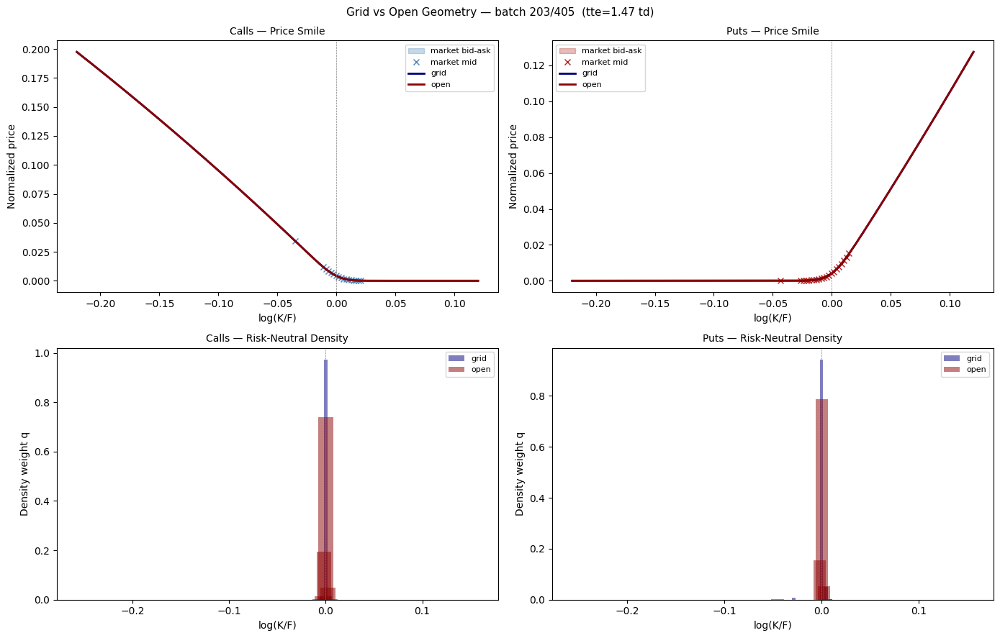

In [28]:
mid_idx = len(results) // 2
r = results[mid_idx]
ts_sel = r["ts"]
snap_c = snaps_calls.filter(pl.col("batch_ts") == ts_sel).sort("pure_strike")
snap_p = snaps_puts.filter(pl.col("batch_ts") == ts_sel).sort("pure_strike")
tte_sn = float(snap_c["T"].median()) if not snap_c.is_empty() else tte_y_med

log_k_dense = np.linspace(-0.22, 0.12, 150)
pk_dense = np.exp(log_k_dense)
tte_dense = np.full(150, tte_sn)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle(
    f"Grid vs Open Geometry — batch {mid_idx + 1}/{len(results)}  (tte={tte_sn * 252:.2f} td)",
    fontsize=11,
)

for col_idx, (side, is_call_p, snap, clr_mkt) in enumerate(
    [
        ("c", True, snap_c, "steelblue"),
        ("p", False, snap_p, "firebrick"),
    ]
):
    ax_sm = axes[0, col_idx]
    ax_dn = axes[1, col_idx]
    ltype = "Calls" if is_call_p else "Puts"

    if not snap.is_empty():
        lk = np.log(snap["pure_strike"].to_numpy())
        bid = snap["bid_norm"].to_numpy()
        ask = snap["ask_norm"].to_numpy()
        ax_sm.fill_between(lk, bid, ask, alpha=0.30, color=clr_mkt, label="market bid-ask")
        ax_sm.plot(lk, (bid + ask) / 2, "x", color=clr_mkt, ms=6, label="market mid")

    for gname, pricer, clr_fit in [
        ("grid", grid_sanos_c if is_call_p else grid_sanos_p, "navy"),
        ("open", open_sanos_c if is_call_p else open_sanos_p, "darkred"),
    ]:
        dlvsqs = r.get(f"{gname}_dlvsqs_{side}")
        fwdvols = r.get(f"{gname}_fwdvols_{side}")
        if dlvsqs is None:
            continue
        try:
            dens = pricer.densities(dlvsqs)
            fitted = pricer.price(
                fwdvols,
                dens,
                opt_strikes=pk_dense,
                opt_tte=tte_dense,
                opt_is_call=np.full(150, is_call_p),
                opt_mask=np.ones(len(pk_dense), dtype=bool),
            )
            ax_sm.plot(log_k_dense, fitted, "-", color=clr_fit, lw=2, label=gname)

            # Density bar chart — density at the single model expiry
            if gname == "grid":
                dens_t = np.asarray(dens)[0]  # shape (N,)
                strk_t = pricer.geometry.xstrikes[1, 1:-1]
            else:
                dens_t = np.asarray(dens[0])  # shape (Nt,)
                strk_t = np.asarray(pricer.geometry.xstrikes[1])[1:-1]

            lk_dn = np.log(strk_t)
            bar_w = np.diff(lk_dn).mean() * 0.7 if len(lk_dn) > 1 else 0.02
            ax_dn.bar(lk_dn, dens_t, width=bar_w, alpha=0.5, color=clr_fit, label=gname)

        except Exception as ex:
            print(f"{gname} {ltype}: {ex}")

    for ax, title_sfx in [(ax_sm, "Price Smile"), (ax_dn, "Risk-Neutral Density")]:
        ax.axvline(0, color="gray", lw=0.5, ls="--")
        ax.set_title(f"{ltype} — {title_sfx}", fontsize=10)
        ax.set_xlabel("log(K/F)")
        ax.legend(fontsize=8)
    ax_sm.set_ylabel("Normalized price")
    ax_dn.set_ylabel("Density weight q")

plt.tight_layout()
plt.show()

In [29]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

mid_idx = len(results) // 2
r = results[mid_idx]
ts_sel = r["ts"]
snap_c = snaps_calls.filter(pl.col("batch_ts") == ts_sel).sort("pure_strike")
snap_p = snaps_puts.filter(pl.col("batch_ts") == ts_sel).sort("pure_strike")
tte_sn = float(snap_c["T"].median()) if not snap_c.is_empty() else tte_y_med

log_k_dense = np.linspace(-0.22, 0.12, 150)
pk_dense = np.exp(log_k_dense)
tte_dense = np.full(150, tte_sn)

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("Calls — Price Smile", "Puts — Price Smile"),
    horizontal_spacing=0.08,
)

for col_idx, (side, is_call_p, snap, clr_mkt) in enumerate(
    [
        ("c", True, snap_c, "steelblue"),
        ("p", False, snap_p, "firebrick"),
    ]
):
    col = col_idx + 1
    ltype = "Calls" if is_call_p else "Puts"
    showlegend_col = col_idx == 0  # only show legend entries once

    # Market bid-ask band + mid
    if not snap.is_empty():
        lk = np.log(snap["pure_strike"].to_numpy())
        bid = snap["bid_norm"].to_numpy()
        ask = snap["ask_norm"].to_numpy()

        # Sort by lk for proper fill
        order = np.argsort(lk)
        lk_s = lk[order]
        bid_s = bid[order]
        ask_s = ask[order]

        # Build the bid-ask band using fill='toself'
        band_x = np.concatenate([lk_s, lk_s[::-1]])
        band_y = np.concatenate([ask_s, bid_s[::-1]])

        # Convert rgb name to rgba with alpha
        rgba_fill = {
            "steelblue": "rgba(70,130,180,0.30)",
            "firebrick": "rgba(178,34,34,0.30)",
        }[clr_mkt]

        fig.add_trace(
            go.Scatter(
                x=band_x,
                y=band_y,
                fill="toself",
                fillcolor=rgba_fill,
                line=dict(color="rgba(0,0,0,0)"),
                hoverinfo="skip",
                name="market bid-ask",
                legendgroup="bidask",
                showlegend=showlegend_col,
            ),
            row=1,
            col=col,
        )

        fig.add_trace(
            go.Scatter(
                x=lk_s,
                y=(bid_s + ask_s) / 2,
                mode="markers",
                marker=dict(symbol="x", size=8, color=clr_mkt),
                name="market mid",
                legendgroup="mid",
                showlegend=showlegend_col,
            ),
            row=1,
            col=col,
        )

    # Fitted curves: grid and open
    for gname, pricer, clr_fit in [
        ("grid", grid_sanos_c if is_call_p else grid_sanos_p, "navy"),
        ("open", open_sanos_c if is_call_p else open_sanos_p, "darkred"),
    ]:
        dlvsqs = r.get(f"{gname}_dlvsqs_{side}")
        fwdvols = r.get(f"{gname}_fwdvols_{side}")
        if dlvsqs is None:
            continue
        try:
            dens = pricer.densities(dlvsqs)
            fitted = pricer.price(
                fwdvols,
                dens,
                opt_strikes=pk_dense,
                opt_tte=tte_dense,
                opt_is_call=np.full(150, is_call_p),
                opt_mask=np.ones(len(pk_dense), dtype=bool),
            )
            fig.add_trace(
                go.Scatter(
                    x=log_k_dense,
                    y=fitted,
                    mode="lines",
                    line=dict(color=clr_fit, width=2),
                    name=gname,
                    legendgroup=gname,
                    showlegend=showlegend_col,
                ),
                row=1,
                col=col,
            )
        except Exception as ex:
            print(f"{gname} {ltype}: {ex}")

    # Vertical dashed line at log(K/F) = 0
    fig.add_vline(
        x=0,
        line=dict(color="gray", width=0.8, dash="dash"),
        row=1,
        col=col,
    )

    fig.update_xaxes(title_text="log(K/F)", row=1, col=col)
    fig.update_yaxes(title_text="Normalized price", row=1, col=col)

fig.update_layout(
    title=dict(
        text=f"Grid vs Open Geometry — batch {mid_idx + 1}/{len(results)}  (tte={tte_sn * 252:.2f} td)",
        font=dict(size=12),
    ),
    height=500,
    width=1200,
    legend=dict(font=dict(size=10)),
    template="plotly_white",
)

fig.show()

## Forward check

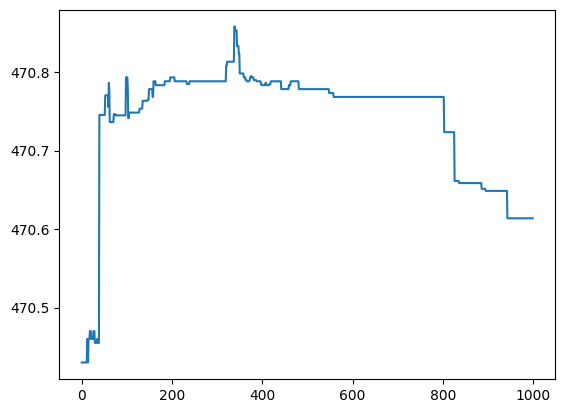

In [30]:
plt.plot(df_quotes.select(pl.col("forward"))[:1000])

In [31]:
diffs = (df_quotes["forward"].shift(1) - df_quotes["forward"]) / df_quotes["forward"]
diffs.filter(diffs != 0).describe()

statistic,value
str,f64
"""count""",75870.0
"""null_count""",0.0
"""mean""",3.8687e-8
"""std""",0.000015
"""min""",-0.000617
"""25%""",-0.000008
"""50%""",-0.000001
"""75%""",0.000008
"""max""",0.00058


In [32]:
df_quotes.select(pl.col("discount_factor")).describe()

statistic,discount_factor
str,f64
"""count""",2.11551e6
"""null_count""",0.0
"""mean""",1.000191
"""std""",0.001662
"""min""",0.998
"""25%""",0.998
"""50%""",1.0
"""75%""",1.002
"""max""",1.002
